# Resultados e análise de erros — TrashNet (MLP × CNN)

Este notebook avalia os 6 modelos salvos no **mesmo conjunto de teste** (379 imagens) e apresenta tabelas, figuras e a discussão.

**Como executar:** rode na **raiz do projeto**, onde estão `modelos/`, `historicos/`, `split.json`, `dataset-resized/`, `common.py` e `05_resultados.py`. Requer TensorFlow, scikit-learn, pandas, matplotlib e Pillow (`requirements.txt`). Os modelos `.keras` estão no Drive indicado no README.

## 1. Avaliação dos modelos
A célula abaixo executa `05_resultados.py`, que avalia os 6 modelos no teste e grava tabelas, previsões por imagem e figuras em `resultados/`.

In [1]:
!python 05_resultados.py

I0000 00:00:1795659716.573455     193 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795659721.911025     193 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 AMX_FP16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795659725.136110     193 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Avaliando mlp_128_sem no teste ...


Avaliando mlp_128_com no teste ...


Avaliando cnn_128_sem no teste ...


... (2 outputs left out)

Avaliando cnn_512_sem no teste ...



 experimento  acuracia_teste  f1_macro_teste  f1_macro_val  tempo_total_s
mlp_128_sem          0.6016          0.5644        0.5050          118.4
mlp_128_com          0.5884          0.5610        0.5024           62.4
cnn_128_sem          0.7335          0.6914        0.6461          114.5
cnn_128_com          0.7124          0.6892        0.6676           86.8
cnn_256_sem          0.7309          0.6725        0.6505          278.2
cnn_512_sem          0.7203          0.6533        0.6484         1140.2



Melhor modelo (F1 macro na validacao): cnn_128_com | erros no teste: 109 de 379


OK! Tudo salvo em resultados


## 2. Tabelas de métricas, custo e desempenho por classe

In [2]:
from IPython.display import Markdown, Image, display
display(Markdown(open("resultados/tabelas.md", encoding="utf-8").read()))

## Metricas e custo (teste)

| experimento   | modelo   | resolucao   | pesos_de_classe   |   acuracia_teste |   f1_macro_teste |   f1_macro_val |   acuracia_val |   parametros |   tamanho_modelo_MB |   epocas |   epoca_modelo_salvo |   tempo_total_s |   tempo_medio_epoca_s |   batch | hardware          |   pico_ram_MB |   pico_gpu_MB | justificativa_lote   |
|:--------------|:---------|:------------|:------------------|-----------------:|-----------------:|---------------:|---------------:|-------------:|--------------------:|---------:|---------------------:|----------------:|----------------------:|--------:|:------------------|--------------:|--------------:|:---------------------|
| mlp_128_sem   | MLP      | 128x96      | Nao               |           0.6016 |           0.5644 |         0.505  |         0.5383 |      9472646 |               36.18 |       67 |                   57 |           118.4 |                  1.77 |      32 | Tesla T4 (x86_64) |        1919.8 |         309.4 |                      |
| mlp_128_com   | MLP      | 128x96      | Sim               |           0.5884 |           0.561  |         0.5024 |         0.5198 |      9472646 |               36.18 |       35 |                   25 |            62.4 |                  1.78 |      32 | Tesla T4 (x86_64) |        2020.2 |         437.1 |                      |
| cnn_128_sem   | CNN      | 128x96      | Nao               |           0.7335 |           0.6914 |         0.6461 |         0.715  |       111430 |                0.49 |       71 |                   61 |           114.5 |                  1.61 |      32 | Tesla T4 (x86_64) |        2007.2 |         717.5 |                      |
| cnn_128_com   | CNN      | 128x96      | Sim               |           0.7124 |           0.6892 |         0.6676 |         0.6887 |       111430 |                0.49 |       60 |                   50 |            86.8 |                  1.45 |      32 | Tesla T4 (x86_64) |        2112   |         717.5 |                      |
| cnn_256_sem   | CNN      | 256x192     | Nao               |           0.7309 |           0.6725 |         0.6505 |         0.7177 |       111430 |                0.49 |       75 |                   65 |           278.2 |                  3.71 |      32 | Tesla T4 (x86_64) |        2869.5 |        2337.2 |                      |
| cnn_512_sem   | CNN      | 512x384     | Nao               |           0.7203 |           0.6533 |         0.6484 |         0.715  |       111430 |                0.49 |       85 |                   75 |          1140.2 |                 13.41 |      32 | Tesla T4 (x86_64) |        4436.3 |        6833.4 |                      |

## Por classe (teste)

| experimento   | classe    |   precisao |   recall |     f1 |   suporte |
|:--------------|:----------|-----------:|---------:|-------:|----------:|
| mlp_128_sem   | glass     |     0.4557 |   0.48   | 0.4675 |        75 |
| mlp_128_sem   | paper     |     0.6168 |   0.7333 | 0.6701 |        90 |
| mlp_128_sem   | cardboard |     0.7857 |   0.7333 | 0.7586 |        60 |
| mlp_128_sem   | plastic   |     0.68   |   0.7083 | 0.6939 |        72 |
| mlp_128_sem   | metal     |     0.5319 |   0.4098 | 0.463  |        61 |
| mlp_128_sem   | trash     |     0.4    |   0.2857 | 0.3333 |        21 |
| mlp_128_com   | glass     |     0.4717 |   0.3333 | 0.3906 |        75 |
| mlp_128_com   | paper     |     0.6408 |   0.7333 | 0.6839 |        90 |
| mlp_128_com   | cardboard |     0.7143 |   0.75   | 0.7317 |        60 |
| mlp_128_com   | plastic   |     0.6622 |   0.6806 | 0.6712 |        72 |
| mlp_128_com   | metal     |     0.4909 |   0.4426 | 0.4655 |        61 |
| mlp_128_com   | trash     |     0.3548 |   0.5238 | 0.4231 |        21 |
| cnn_128_sem   | glass     |     0.5588 |   0.76   | 0.6441 |        75 |
| cnn_128_sem   | paper     |     0.75   |   0.8667 | 0.8041 |        90 |
| cnn_128_sem   | cardboard |     0.9032 |   0.9333 | 0.918  |        60 |
| cnn_128_sem   | plastic   |     0.8281 |   0.7361 | 0.7794 |        72 |
| cnn_128_sem   | metal     |     0.7297 |   0.4426 | 0.551  |        61 |
| cnn_128_sem   | trash     |     0.7    |   0.3333 | 0.4516 |        21 |
| cnn_128_com   | glass     |     0.6479 |   0.6133 | 0.6301 |        75 |
| cnn_128_com   | paper     |     0.8068 |   0.7889 | 0.7978 |        90 |
| cnn_128_com   | cardboard |     0.8889 |   0.9333 | 0.9106 |        60 |
| cnn_128_com   | plastic   |     0.7969 |   0.7083 | 0.75   |        72 |
| cnn_128_com   | metal     |     0.6923 |   0.4426 | 0.54   |        61 |
| cnn_128_com   | trash     |     0.3519 |   0.9048 | 0.5067 |        21 |
| cnn_256_sem   | glass     |     0.5398 |   0.8133 | 0.6489 |        75 |
| cnn_256_sem   | paper     |     0.78   |   0.8667 | 0.8211 |        90 |
| cnn_256_sem   | cardboard |     0.9032 |   0.9333 | 0.918  |        60 |
| cnn_256_sem   | plastic   |     0.8387 |   0.7222 | 0.7761 |        72 |
| cnn_256_sem   | metal     |     0.7353 |   0.4098 | 0.5263 |        61 |
| cnn_256_sem   | trash     |     0.625  |   0.2381 | 0.3448 |        21 |
| cnn_512_sem   | glass     |     0.5172 |   0.8    | 0.6283 |        75 |
| cnn_512_sem   | paper     |     0.798  |   0.8778 | 0.836  |        90 |
| cnn_512_sem   | cardboard |     0.9153 |   0.9    | 0.9076 |        60 |
| cnn_512_sem   | plastic   |     0.8308 |   0.75   | 0.7883 |        72 |
| cnn_512_sem   | metal     |     0.6471 |   0.3607 | 0.4632 |        61 |
| cnn_512_sem   | trash     |     0.6667 |   0.1905 | 0.2963 |        21 |


## 3. Figuras
Matrizes de confusão (teste), curvas de aprendizagem, efeito da resolução (CNN sem pesos) e erros do modelo selecionado.

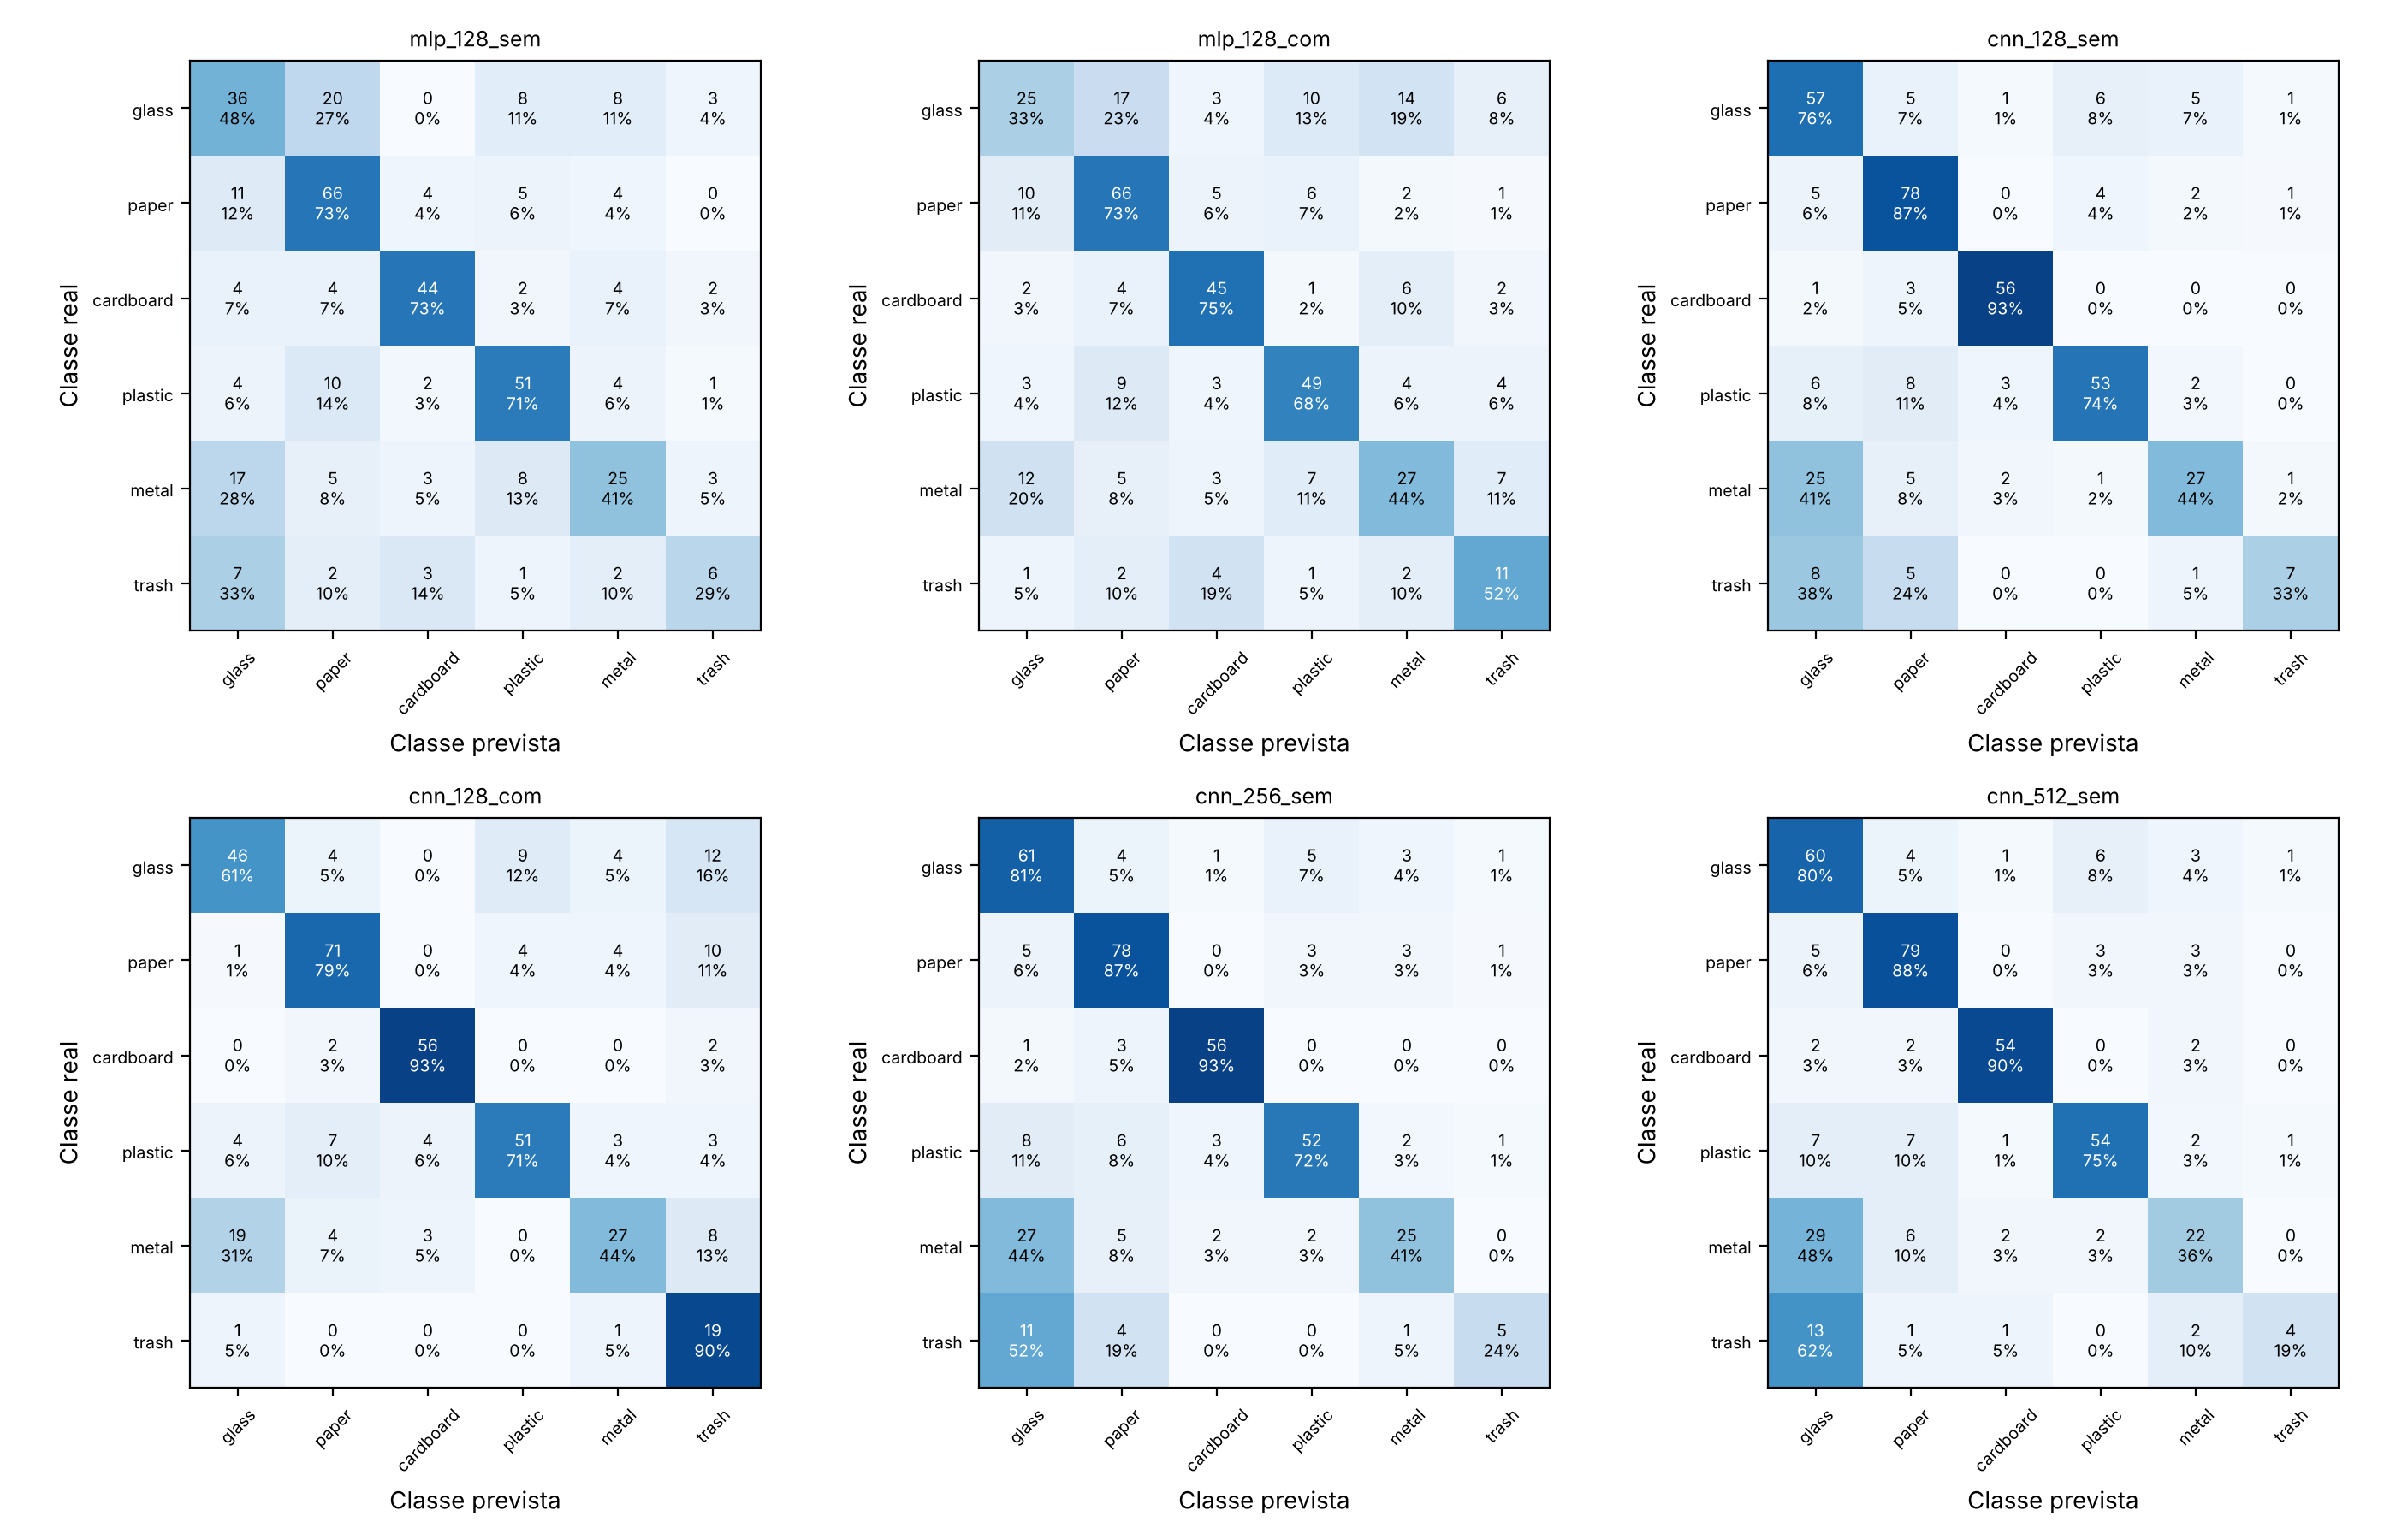

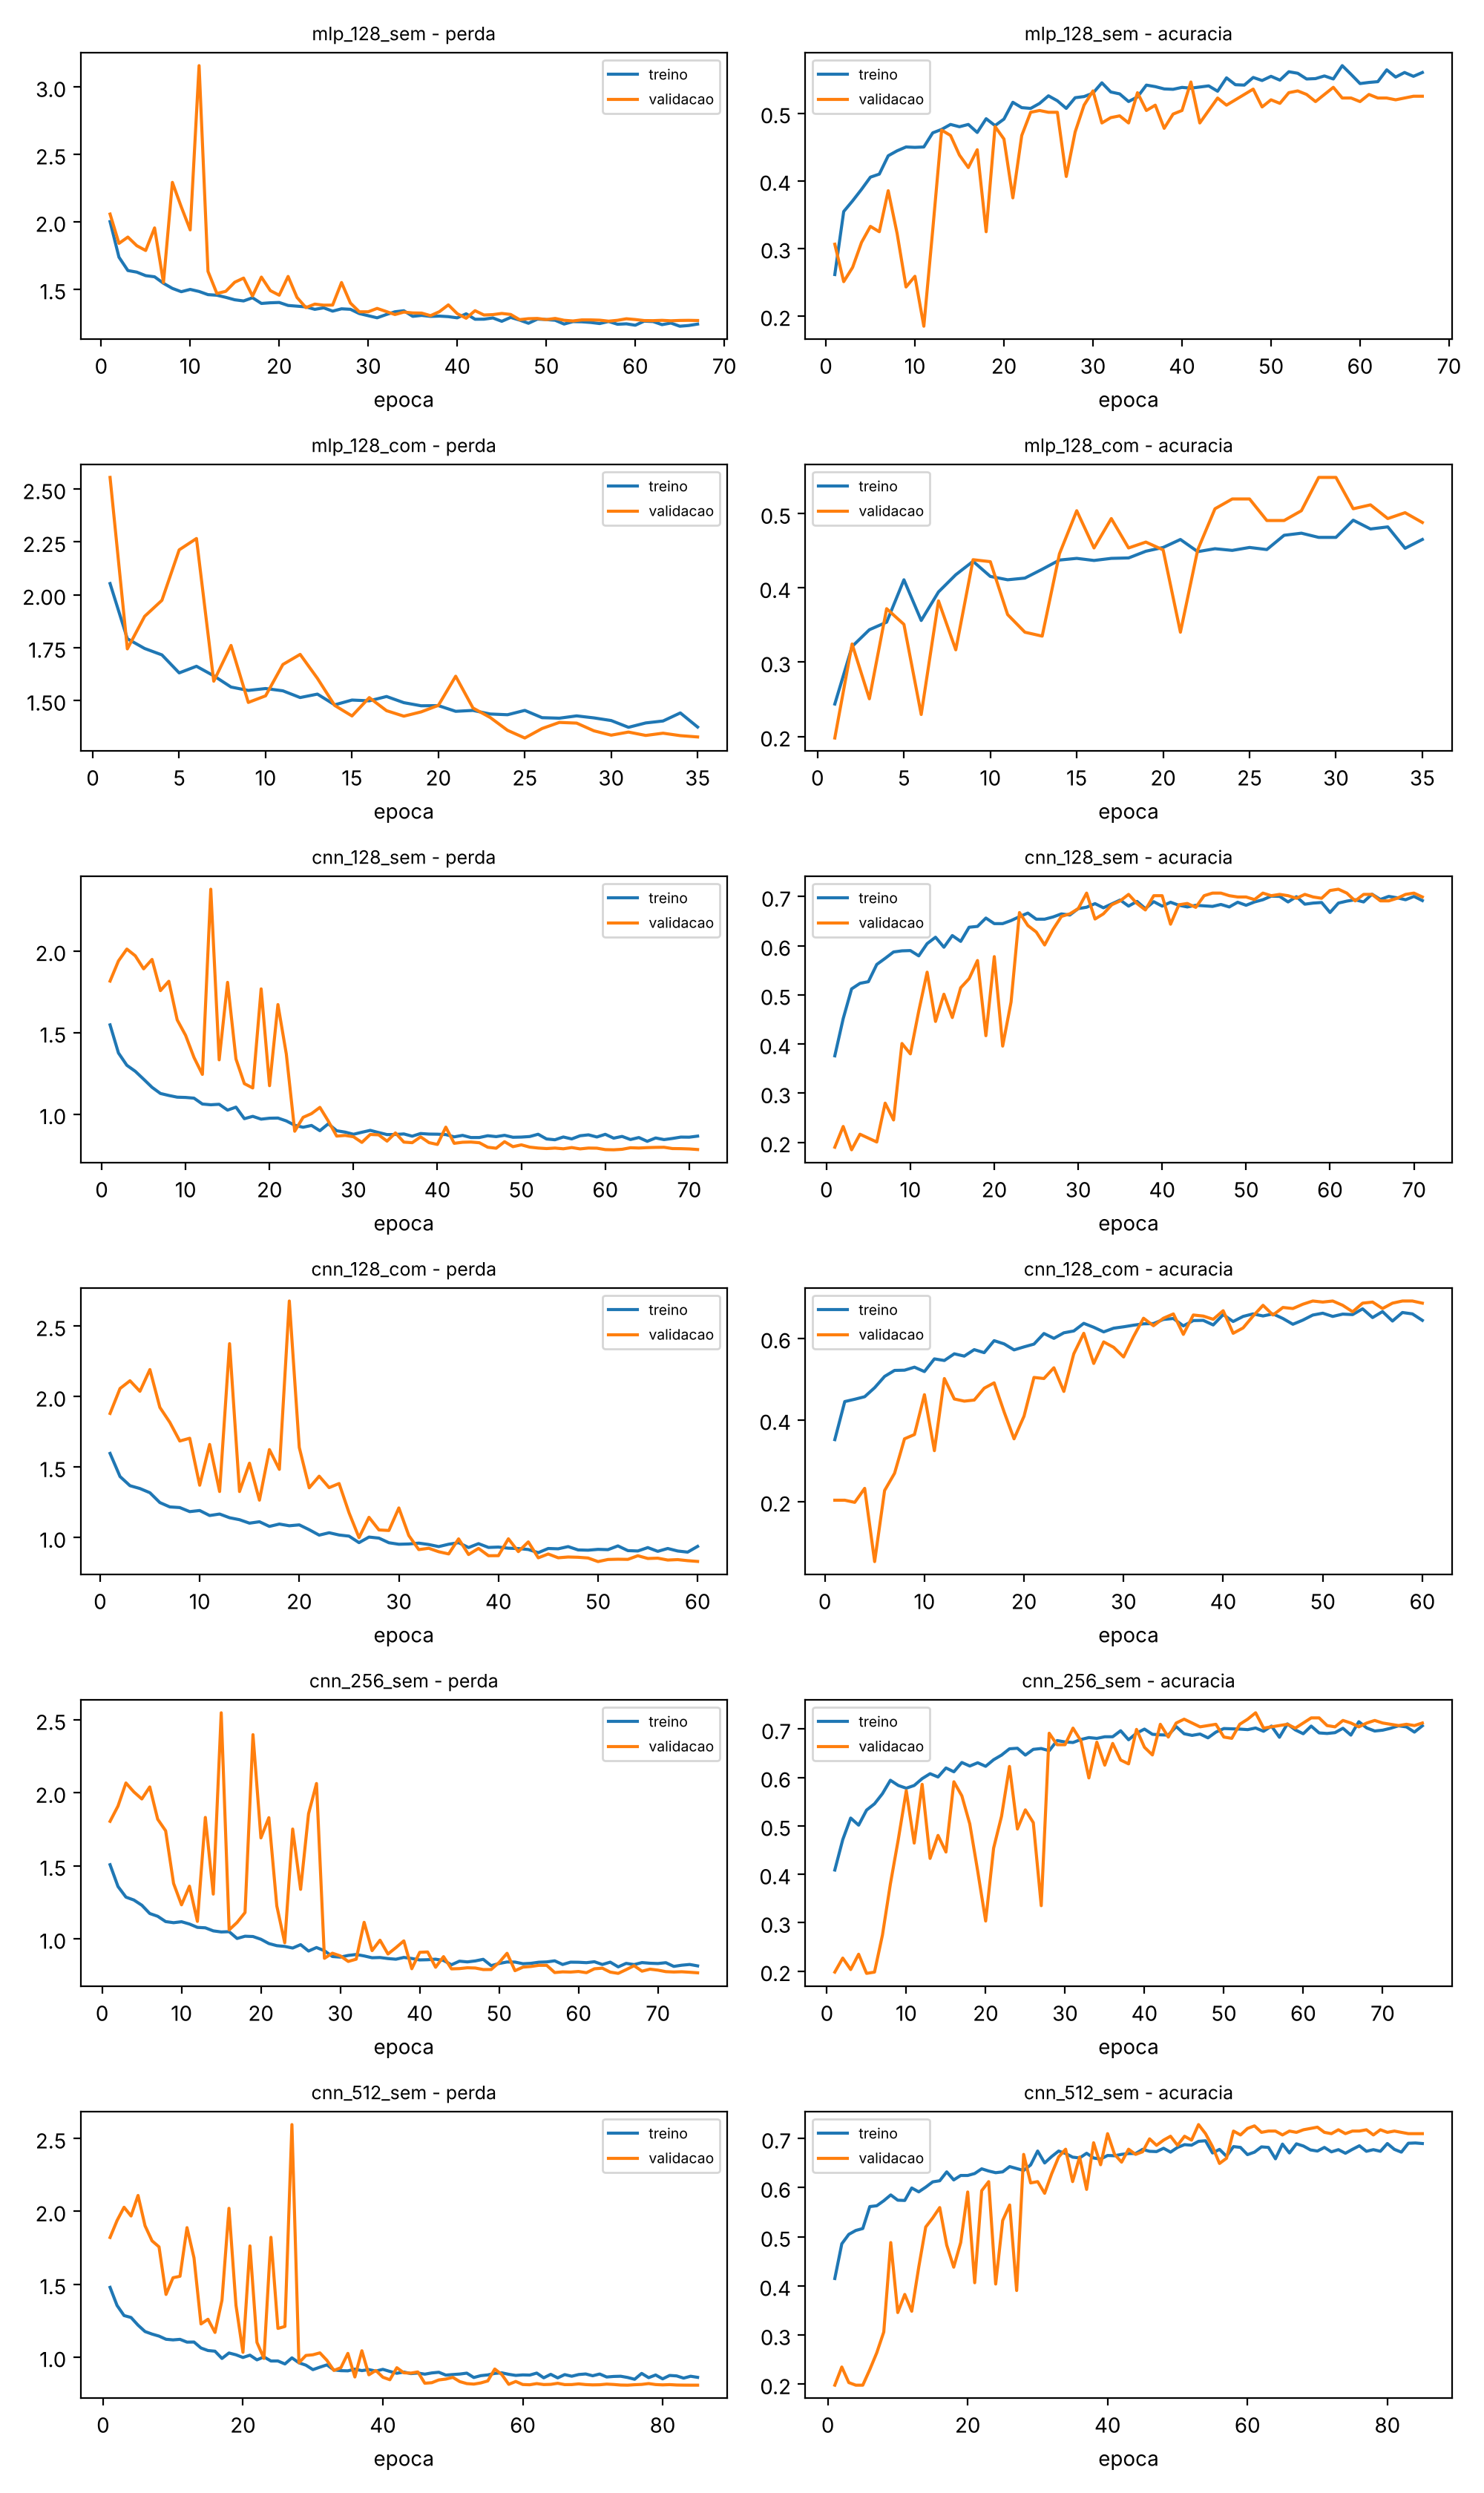

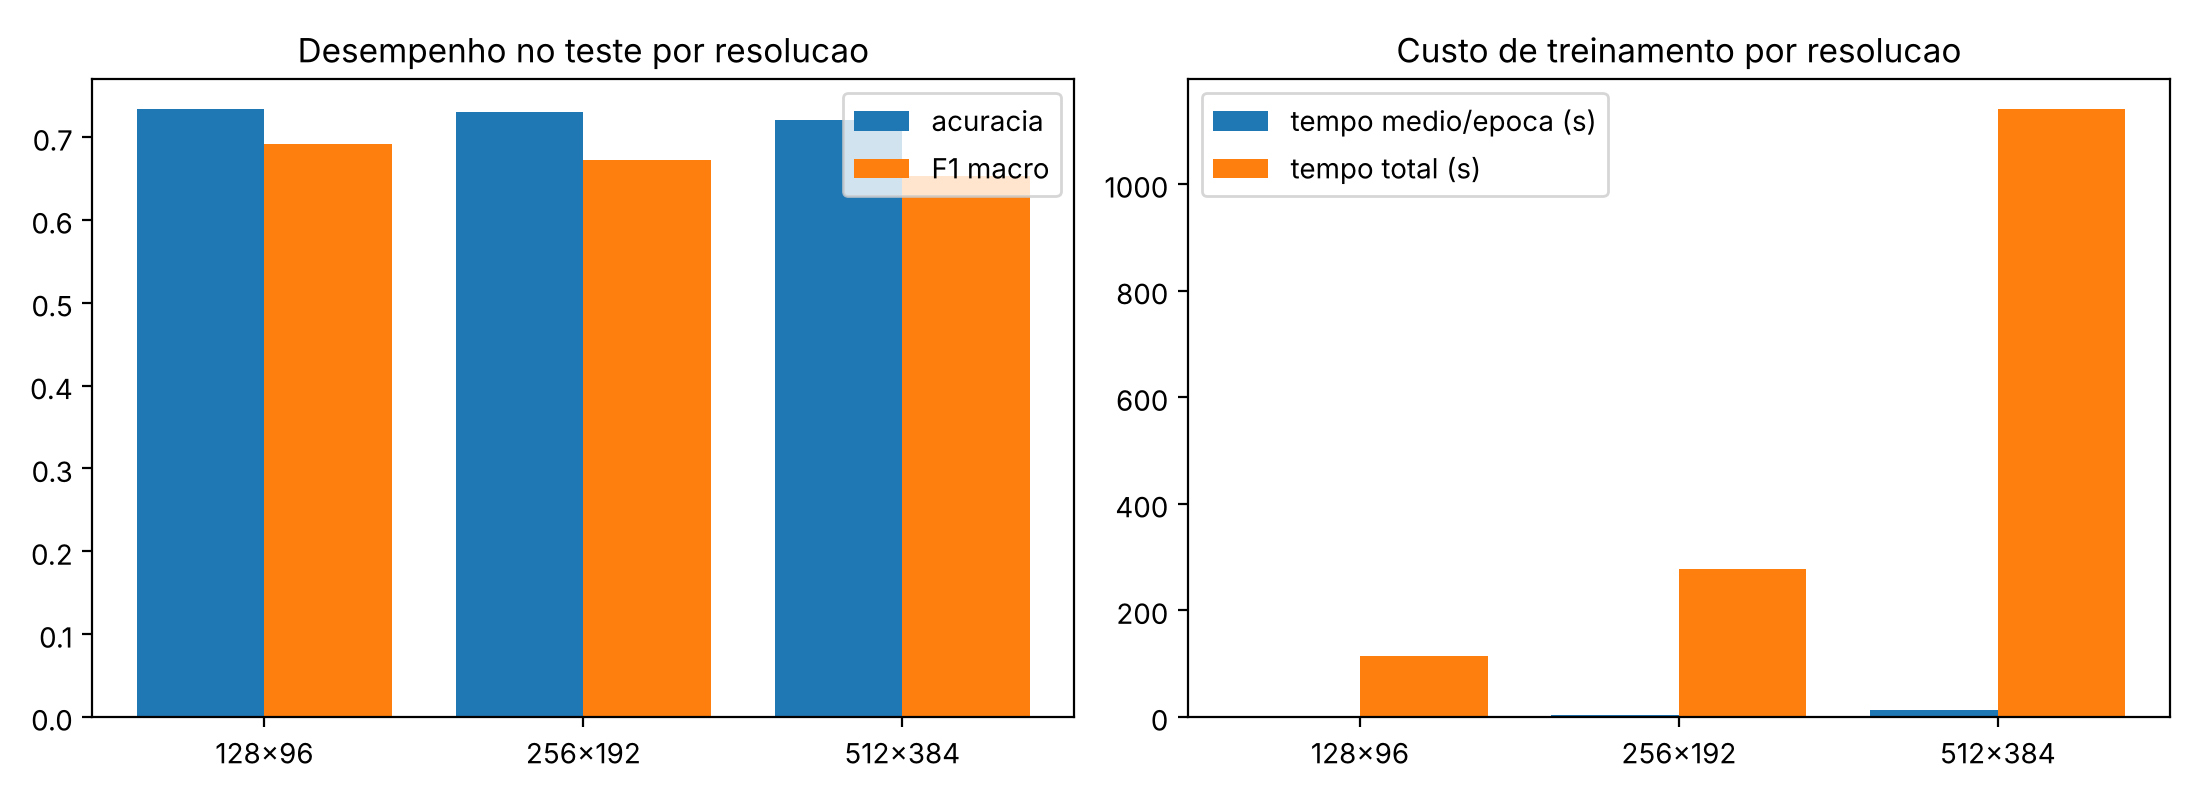

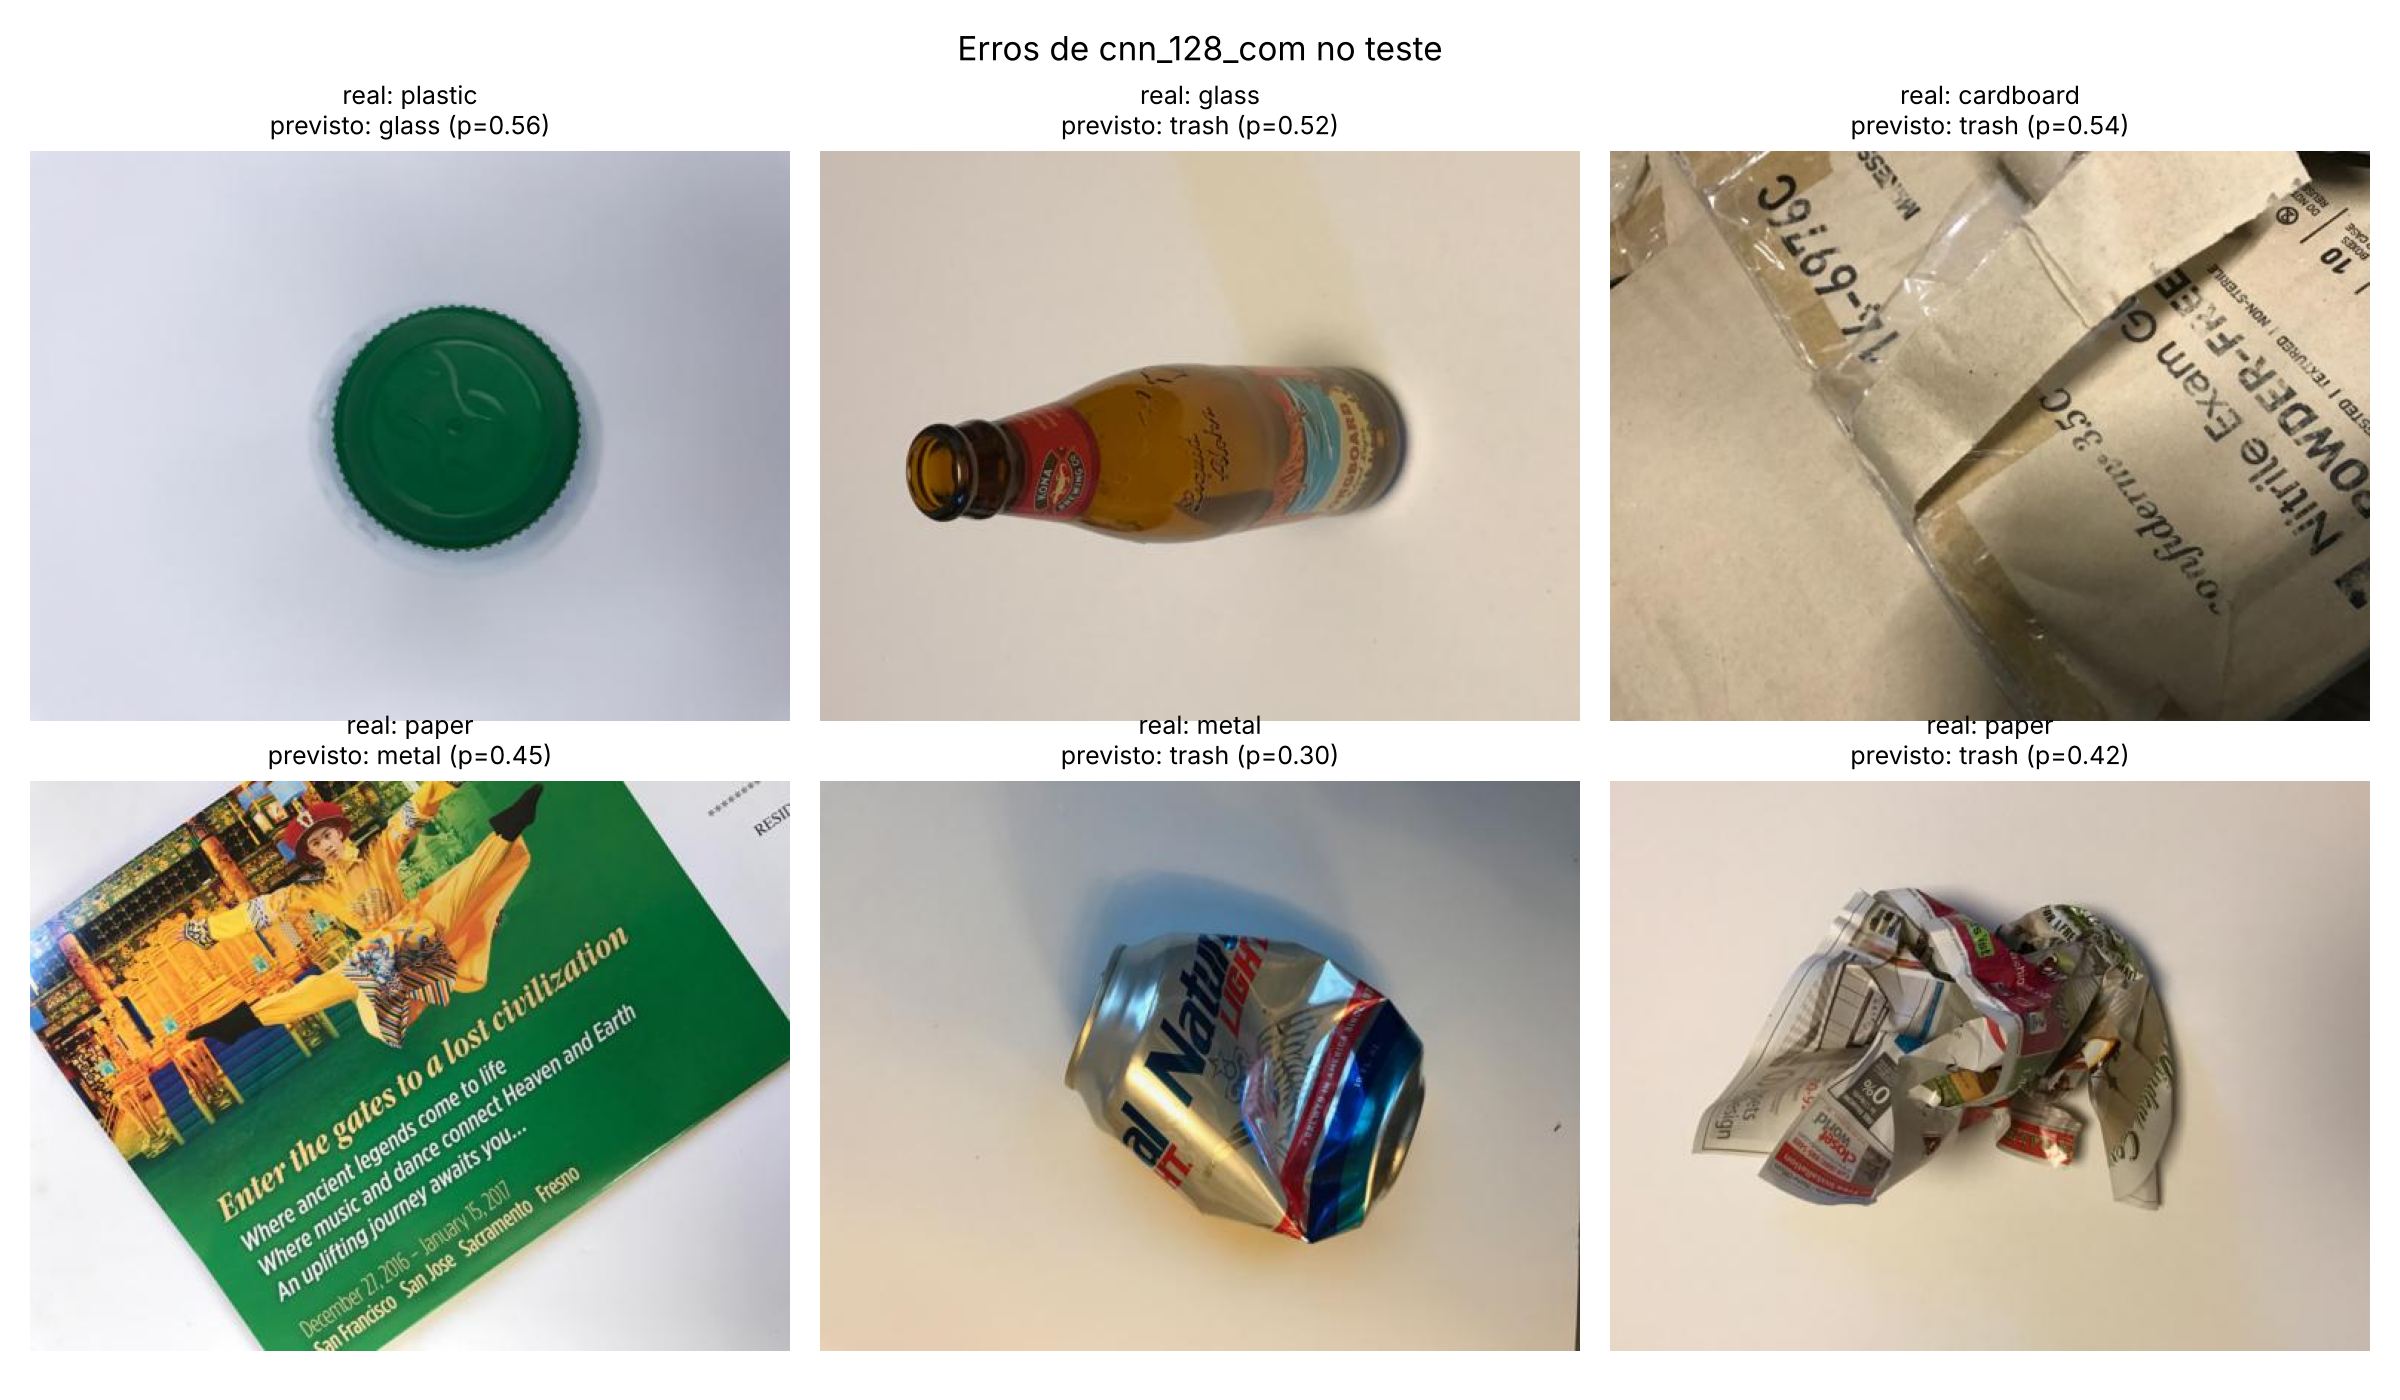

In [3]:
for f in ["matrizes_confusao", "curvas_aprendizagem", "efeito_resolucao", "erros_melhor_modelo"]:
    display(Image(f"resultados/figuras/{f}.png"))

## 4. Discussão

### Metodologia da avaliação

Os seis experimentos foram avaliados no mesmo conjunto de teste (379 imagens), uma única vez, sem ajuste posterior de hiperparâmetros. A seleção do modelo foi feita pelo **F1 macro de validação**; o teste serve apenas para o relato final. O split (70/15/15, semente 42) e os pesos de classe vêm do `split.json` da equipe. As CNNs de 128, 256 e 512 usam a mesma arquitetura (111.430 parâmetros) e foram treinadas na mesma GPU (Tesla T4), com lote 32.

### Desempenho comparativo (Tabela 1)

| Experimento | Acurácia (teste) | F1 macro (teste) | F1 macro (validação) |
|---|---|---|---|
| mlp_128_sem | 0,6016 | 0,5644 | 0,5050 |
| mlp_128_com | 0,5884 | 0,5610 | 0,5024 |
| cnn_128_sem | 0,7335 | 0,6914 | 0,6461 |
| cnn_128_com | 0,7124 | 0,6892 | 0,6676 |
| cnn_256_sem | 0,7309 | 0,6725 | 0,6505 |
| cnn_512_sem | 0,7203 | 0,6533 | 0,6484 |

As CNNs superaram os MLPs nas duas métricas. A acurácia de teste foi de 0,59 a 0,60 nos MLPs e de 0,72 a 0,73 nas CNNs. O MLP tem 9.472.646 parâmetros; a CNN, 111.430, ou seja, cerca de 85 vezes menos. Uma possível explicação é que as convoluções aproveitam a estrutura espacial da imagem, e o MLP, que recebe os pixels achatados, não; este trabalho não testou essa causa isoladamente.

### Modelo selecionado

Pelo critério de maior F1 macro de validação, o modelo selecionado foi o **cnn_128_com** (0,6676). No teste, ele teve acurácia 0,7124, F1 macro 0,6892 e **109 erros em 379 imagens**. Ele não foi o melhor no teste: o cnn_128_sem teve acurácia 0,7335 e F1 macro 0,6914. Isso é esperado, porque a seleção usou só a validação. As diferenças entre os modelos de 128 são de poucas imagens (0,7335 contra 0,7124 corresponde a 8 imagens), então não devem ser tratadas como superioridade clara.

### Desempenho por classe e confusões

No cnn_128_com, os 109 erros se distribuem por classe real assim: metal 34, glass 29, plastic 21, paper 19, cardboard 4 e trash 2. A classe cardboard teve o maior F1 nas CNNs (0,908 a 0,918 em todos os modelos CNN). Metal teve recall de 0,443 nesse modelo.

A confusão mais frequente nas CNNs foi **metal previsto como glass**: 25 imagens no cnn_128_sem, 19 no cnn_128_com, 27 no cnn_256_sem e 29 no cnn_512_sem. Nos MLPs, o maior erro foi glass previsto como paper (20 e 17 imagens). Possível explicação: objetos de metal e de vidro costumam ser brilhantes ou refletivos, e nas fotos de baixa resolução isso pode se parecer; é uma hipótese, não foi medida.

### Efeito dos pesos de classe na classe trash

Trash tem apenas 21 imagens no teste, então cada erro altera o recall em 4,8 pontos percentuais.

| Modelo | Precisão trash | Recall trash | F1 trash |
|---|---|---|---|
| mlp_128_sem | 0,400 | 0,286 | 0,333 |
| mlp_128_com | 0,355 | 0,524 | 0,423 |
| cnn_128_sem | 0,700 | 0,333 | 0,452 |
| cnn_128_com | 0,352 | 0,905 | 0,507 |

Os pesos de classe aumentaram o recall de trash nos dois modelos (+0,238 no MLP, +0,571 na CNN) e reduziram a precisão (−0,045 e −0,348). O cnn_128_com previu trash 54 vezes e acertou 19; os 35 falsos positivos vieram principalmente de glass (12), paper (10) e metal (8). Ou seja, o ganho de cobertura veio com mais falsos positivos. No conjunto, os pesos não melhoraram as métricas globais: o F1 macro de teste foi 0,6914 sem pesos e 0,6892 com pesos na CNN, e 0,5644 e 0,5610 no MLP.

### Curvas de aprendizagem e sobreajuste

Diferença entre treino e validação na época do modelo salvo (acurácia de treino menos acurácia de validação):

| Experimento | Época salva | Gap de acurácia | Gap de perda (val − treino) |
|---|---|---|---|
| mlp_128_sem | 57 | +0,012 | +0,002 |
| mlp_128_com | 25 | −0,065 | −0,131 |
| cnn_128_sem | 61 | −0,028 | −0,071 |
| cnn_128_com | 50 | −0,027 | −0,087 |
| cnn_256_sem | 65 | −0,016 | −0,044 |
| cnn_512_sem | 75 | −0,037 | −0,053 |

Os gaps são pequenos e, em cinco dos seis experimentos, a acurácia de validação ficou acima da de treino. Isso não indica sobreajuste forte. Uma possível explicação é que a métrica de treino é calculada com Dropout ativo, o que a deixa mais baixa; isso não foi testado aqui. **[CONFERIR]** na figura das curvas se a perda de validação sobe de forma sustentada enquanto a de treino cai em algum experimento, e se as oscilações iniciais da validação diminuem nas épocas finais.

### Resolução versus custo (CNN sem pesos)

| Resolução | Acurácia (teste) | F1 macro (teste) | F1 macro (val.) | Tempo total | Tempo/época | Pico GPU | Pico RAM |
|---|---|---|---|---|---|---|---|
| 128×96 | 0,7335 | 0,6914 | 0,6461 | 114,5 s | 1,61 s | 717,5 MB | 2.007 MB |
| 256×192 | 0,7309 | 0,6725 | 0,6505 | 278,2 s | 3,71 s | 2.337,2 MB | 2.870 MB |
| 512×384 | 0,7203 | 0,6533 | 0,6484 | 1.140,2 s | 13,41 s | 6.833,4 MB | 4.436 MB |

Com a mesma arquitetura (111.430 parâmetros), o mesmo lote (32) e a mesma GPU, aumentar a resolução **não trouxe ganho observado** no teste: a acurácia foi 0,7335, 0,7309 e 0,7203, uma diferença de 1 e 5 imagens em 379. Na validação, o F1 macro ficou praticamente igual nas três resoluções (0,646, 0,651 e 0,648). O custo, porém, cresceu muito: o tempo total foi cerca de 2,4 vezes maior em 256 e 10,0 vezes maior em 512; o pico de memória da GPU, cerca de 3,3 e 9,5 vezes. A camada de pooling global mantém o número de parâmetros constante, então o custo extra vem do tamanho das ativações, não do tamanho do modelo. Nesta configuração, a resolução maior não compensou o custo. A conclusão vale para este experimento (uma rodada por configuração, semente 42); o treinamento não é determinístico, e outra rodada poderia variar um pouco.

### Análise de erros do modelo selecionado (cnn_128_com)

O modelo errou 109 das 379 imagens de teste (28,8%). Em 90 desses erros (82,6%), a probabilidade atribuída à classe prevista foi menor que 0,6, e a média foi 0,48, o que indica que muitos erros ocorreram com baixa confiança.

Os pares real → previsto mais frequentes foram metal→glass (19), glass→trash (12), paper→trash (10), glass→plastic (9), metal→trash (8) e plastic→paper (7).

A figura mostra os seis primeiros erros da lista, não uma seleção por gravidade:

| Imagem | Real | Previsto | Prob. prevista | O que se vê |
|---|---|---|---|---|
| plastic294 | plastic | glass | 0,56 | tampa verde sobre fundo branco |
| glass95 | glass | trash | 0,52 | garrafa de cerveja marrom |
| cardboard302 | cardboard | trash | 0,54 | papelão com fita e texto, em close |
| paper358 | paper | metal | 0,45 | folheto verde colorido |
| metal90 | metal | trash | 0,30 | lata amassada |
| paper394 | paper | trash | 0,42 | jornal amassado |

Possíveis explicações, todas hipóteses: (a) objetos amassados (lata, jornal) perdem a forma típica da classe e se parecem com o que é visto em trash; (b) o peso de classe alto de trash (3,07) empurra as previsões incertas para essa classe, o que combina com os 54 casos previstos como trash; (c) o conjunto tem 3 pares de imagens idênticas com rótulos diferentes (glass com metal ou plastic), todas no treino, o que pode ter ensinado ao modelo sinais contraditórios; (d) fotos com muito texto ou cor forte (folheto) podem não ter os traços esperados da classe.

Limitações: trash tem 21 imagens no teste; o resultado vem de uma única rodada de treino; e o conjunto de teste tem 379 imagens, então diferenças de 1 a 5 imagens não são conclusivas.